# Homework 12: GPTQ Quantization and Knowledge Distillation
SID4 = 5330, SEED = 5330, HP_ID = 2 (HP_ID adds no extra setting in this homework).

All outputs come from one Google Colab Tesla T4 session. Progress bars and library log lines are trimmed from the saved outputs.

In [1]:
%pip install -q optimum gptqmodel
%pip uninstall -q -y torchaudio torchvision

In [2]:
import os, time, gc, torch, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch.nn.functional as F
from datasets import load_dataset
from huggingface_hub import model_info
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSequenceClassification, GPTQConfig

SEED = 5330
torch.manual_seed(SEED); np.random.seed(SEED)
dev = "cuda"
print(torch.cuda.get_device_name(0))

def size_mb(path):
    return sum(os.path.getsize(os.path.join(path, f)) for f in os.listdir(path)) / 1e6

def free():
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

@torch.no_grad()
def latency(fn, n=50):
    for _ in range(5): fn()
    t = []
    for _ in range(n):
        torch.cuda.synchronize(); s = time.perf_counter(); fn(); torch.cuda.synchronize()
        t.append((time.perf_counter() - s) * 1000)
    return f"{np.percentile(t, 50):.1f} / {np.percentile(t, 95):.1f}"

Tesla T4


## Part 1: GPTQ on the base LLM

In [3]:
MODEL_ID = "facebook/opt-125m"
REV = model_info(MODEL_ID).sha
print("Base model:", MODEL_ID, "revision:", REV)

tok = AutoTokenizer.from_pretrained(MODEL_ID, revision=REV)
wiki = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")
test_ids = tok("\n\n".join(wiki["test"]["text"]), return_tensors="pt").input_ids
prompt = tok("The history of natural language processing began", return_tensors="pt").to(dev)

@torch.no_grad()
def measure_llm(model, path, L=1024):
    free()
    nll = [model(test_ids[:, i:i + L].to(dev), labels=test_ids[:, i:i + L].to(dev)).loss.float() for i in range(0, test_ids.size(1) - L, L)]
    ppl = torch.exp(torch.stack(nll).mean()).item()
    lat = latency(lambda: model.generate(**prompt, min_new_tokens=32, max_new_tokens=32, do_sample=False))
    return [round(ppl, 2), lat, round(torch.cuda.max_memory_allocated() / 1e9, 3), round(size_mb(path), 1)]

base = AutoModelForCausalLM.from_pretrained(MODEL_ID, revision=REV).to(dev).eval()
base.save_pretrained("llm_base")
rows = {"Base LLM": measure_llm(base, "llm_base")}
print(rows)
del base

Base model: facebook/opt-125m revision: 27dcfa74d334bc871f3234de431e71c6eeba5dd6
{'Base LLM': [31.76, '291.6 / 395.8', 0.805, 250.5]}


Quantize with GPTQ, reload from disk, evaluate the same way.

In [4]:
calib = [t for t in wiki["train"]["text"] if len(t) > 1000][:128]
q = AutoModelForCausalLM.from_pretrained(MODEL_ID, revision=REV, device_map="auto",
                                         quantization_config=GPTQConfig(bits=4, dataset=calib, tokenizer=tok))
q.save_pretrained("llm_gptq")
del q
q = AutoModelForCausalLM.from_pretrained("llm_gptq", device_map="auto").eval()
rows["GPTQ quantized LLM"] = measure_llm(q, "llm_gptq")
del q; free()
print(pd.DataFrame(rows, index=["Wikitext2 perplexity", "p50 / p95 latency (ms)", "Peak memory (GB)", "Size on disk (MB)"]).T.to_string())

INFO  Packing Kernel: Auto-selection: adding candidate `TritonV2Linear`
INFO  Kernel: selected -> `TritonV2Linear`.
INFO  Kernel: Auto-selection: adding candidate `ExllamaV2Linear`
INFO  Kernel: selected -> `ExllamaV2Linear`.
                   Wikitext2 perplexity p50 / p95 latency (ms) Peak memory (GB) Size on disk (MB)
Base LLM                          31.76          291.6 / 395.8            0.805             250.5
GPTQ quantized LLM                34.13          558.9 / 731.8             0.68             125.3


## Findings (Table HW11.1: GPTQ comparison on the same LLM and task)
Base model `facebook/opt-125m`, revision `27dcfa74d334bc871f3234de431e71c6eeba5dd6`, used unchanged for both runs. GPTQ at 4 bits with default settings, calibrated on 128 Wikitext2 train passages. Both models evaluated on the Wikitext2 test split on the same Tesla T4. Latency is generation of 32 tokens from a fixed prompt, 50 timed runs after 5 warmups.

| Configuration | Quality metric (perplexity) | p50 / p95 latency (ms) | Peak memory (GB) | Size on disk (MB) |
|---|---|---|---|---|
| Base LLM | 31.76 | 291.6 / 395.8 | 0.805 | 250.5 |
| GPTQ quantized LLM | 34.13 | 558.9 / 731.8 | 0.680 | 125.3 |

* Size on disk is cut in half and peak GPU memory drops about 16 percent. The ratio is 2x and not 4x because the base checkpoint is already stored in 16 bit floats and the embeddings are not quantized.
* Quality cost is small: perplexity rises by 2.37 (about 7.5 percent).
* Latency got worse, not better. The 4 bit weights are unpacked by a custom kernel on every forward pass, so on a model this small GPTQ buys memory and storage, not speed.

## Part 2: Knowledge distillation on AG News
Teacher: the provided `teacher_model` folder (BERT base), loaded locally. Student: `distilbert-base-uncased`. Load the teacher and extract logits for all training samples.

In [5]:
TEACHER, STUDENT = "teacher_model", "distilbert-base-uncased"
ds = load_dataset("fancyzhx/ag_news")
names = ds["train"].features["label"].names
stok = AutoTokenizer.from_pretrained(STUDENT)
assert stok.get_vocab() == AutoTokenizer.from_pretrained(TEACHER).get_vocab()

def enc(split):
    e = stok(list(ds[split]["text"]), truncation=True, max_length=128, padding="max_length", return_tensors="pt")
    return e.input_ids, e.attention_mask, torch.tensor(ds[split]["label"])
Xtr, Mtr, Ytr = enc("train"); Xte, Mte, Yte = enc("test")

def forward(model, X, M, b):
    n = M[b].sum(1).max()
    with torch.autocast("cuda", dtype=torch.float16):
        return model(input_ids=X[b, :n].to(dev), attention_mask=M[b, :n].to(dev)).logits.float()

@torch.no_grad()
def logits(model, X, M, bs=256):
    model.eval()
    return torch.cat([forward(model, X, M, slice(i, i + bs)).cpu() for i in range(0, len(X), bs)])

teacher = AutoModelForSequenceClassification.from_pretrained(TEACHER).to(dev)
t_logits = logits(teacher, Xtr, Mtr)
print("Teacher logits:", tuple(t_logits.shape), "train accuracy:", round((t_logits.argmax(1) == Ytr).float().mean().item(), 4))
del teacher; free()

Teacher logits: (120000, 4) train accuracy: 0.9895


Distillation with loss = alpha * CE + (1 - alpha) * KLD. KLD uses temperature T and is scaled by T squared. Each student restarts from the pretrained checkpoint with SEED; 1 epoch, batch 64, AdamW, learning rate 5e-5. Temperature sweep at alpha 0.5, then alpha sweep at the best temperature.

In [6]:
def train(T, alpha, bs=64, lr=5e-5):
    torch.manual_seed(SEED)
    s = AutoModelForSequenceClassification.from_pretrained(STUDENT, num_labels=4).to(dev).train()
    opt, scaler, log = torch.optim.AdamW(s.parameters(), lr=lr), torch.amp.GradScaler(), []
    perm = torch.randperm(len(Xtr))
    for step, i in enumerate(range(0, len(perm), bs)):
        b = perm[i:i + bs]
        out = forward(s, Xtr, Mtr, b)
        ce = F.cross_entropy(out, Ytr[b].to(dev))
        kld = F.kl_div(F.log_softmax(out / T, -1), F.softmax(t_logits[b].to(dev) / T, -1), reduction="batchmean") * T * T
        loss = alpha * ce + (1 - alpha) * kld
        opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        if step % 50 == 0: log.append((step, loss.item(), ce.item(), kld.item()))
        if step % 300 == 0: print(f"T={T} alpha={alpha} step {step:4d} loss {loss.item():.4f} ce {ce.item():.4f} kld {kld.item():.4f}")
    acc = (logits(s, Xte, Mte).argmax(1) == Yte).float().mean().item()
    path = f"student_T{T}_a{alpha}"; s.save_pretrained(path)
    print(f"T={T} alpha={alpha} test accuracy {acc:.4f}\n")
    return dict(T=T, alpha=alpha, acc=acc, log=log, path=path)

t_runs = [train(T, 0.5) for T in (1, 2, 5, 10)]
best_run = max(t_runs, key=lambda r: r["acc"]); best_T = best_run["T"]
a_runs = [train(best_T, 0.25), best_run, train(best_T, 0.75)]  # alpha=0.5 at best_T is the same seeded run as in the sweep

T=1 alpha=0.5 step    0 loss 1.3860 ce 1.3946 kld 1.3774
T=1 alpha=0.5 step  300 loss 0.0928 ce 0.0829 kld 0.1027
T=1 alpha=0.5 step  600 loss 0.3121 ce 0.2882 kld 0.3361
T=1 alpha=0.5 step  900 loss 0.1677 ce 0.1733 kld 0.1621
T=1 alpha=0.5 step 1200 loss 0.1100 ce 0.1122 kld 0.1077
T=1 alpha=0.5 step 1500 loss 0.1725 ce 0.1761 kld 0.1688
T=1 alpha=0.5 step 1800 loss 0.1115 ce 0.1505 kld 0.0726
T=1 alpha=0.5 test accuracy 0.9446

T=2 alpha=0.5 step    0 loss 3.0530 ce 1.3946 kld 4.7114
T=2 alpha=0.5 step  300 loss 0.1937 ce 0.0447 kld 0.3427
T=2 alpha=0.5 step  600 loss 0.6197 ce 0.3354 kld 0.9041
T=2 alpha=0.5 step  900 loss 0.2070 ce 0.1095 kld 0.3046
T=2 alpha=0.5 step 1200 loss 0.1039 ce 0.0323 kld 0.1756
T=2 alpha=0.5 step 1500 loss 0.3101 ce 0.1872 kld 0.4330
T=2 alpha=0.5 step 1800 loss 0.1609 ce 0.1578 kld 0.1639
T=2 alpha=0.5 test accuracy 0.9411

T=5 alpha=0.5 step    0 loss 5.5983 ce 1.3946 kld 9.8019
T=5 alpha=0.5 step  300 loss 0.3103 ce 0.0421 kld 0.5786
T=5 alpha=0.5 st

Best temperature: 1
 T  alpha    acc
 1    0.5 0.9446
 2    0.5 0.9411
 5    0.5 0.9432
10    0.5 0.9445 

 T  alpha    acc
 1   0.25 0.9428
 1   0.50 0.9446
 1   0.75 0.9429


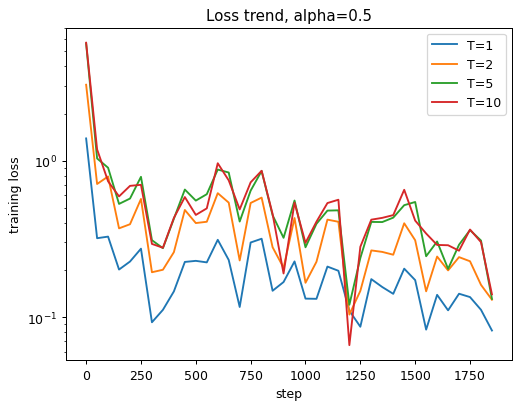

In [7]:
for r in t_runs:
    plt.plot(*zip(*[(l[0], l[1]) for l in r["log"]]), label=f"T={r['T']}")
plt.xlabel("step"); plt.ylabel("training loss"); plt.yscale("log"); plt.legend(); plt.title("Loss trend, alpha=0.5"); plt.show()
print("Best temperature:", best_T)
print(pd.DataFrame(t_runs)[["T", "alpha", "acc"]].round(4).to_string(index=False), "\n")
print(pd.DataFrame(a_runs)[["T", "alpha", "acc"]].round(4).to_string(index=False))

Teacher vs best student on the AG News test set, same GPU.

In [8]:
def measure_clf(path):
    free()
    m = AutoModelForSequenceClassification.from_pretrained(path).to(dev).eval()
    s = time.perf_counter(); pred = logits(m, Xte, Mte).argmax(1); total = time.perf_counter() - s
    lat = latency(lambda: forward(m, Xte, Mte, slice(0, 1)))
    row = [round((pred == Yte).float().mean().item(), 4), lat, round(torch.cuda.max_memory_allocated() / 1e9, 3), round(size_mb(path), 1), round(total, 1)]
    del m
    return pred, row

best = max(t_runs + a_runs, key=lambda r: r["acc"])
t_pred, t_row = measure_clf(TEACHER)
s_pred, s_row = measure_clf(best["path"])
print("Best student:", best["path"])
print(pd.DataFrame({"Teacher (BERT base)": t_row, "Best distilled student": s_row},
                   index=["Accuracy", "p50 / p95 latency (ms)", "Peak memory (GB)", "Size on disk (MB)", "Test set inference time (s)"]).T.to_string())

Best student: student_T1_a0.5
                       Accuracy p50 / p95 latency (ms) Peak memory (GB) Size on disk (MB) Test set inference time (s)
Teacher (BERT base)      0.9443            12.6 / 15.3            1.368             438.9                        12.9
Best distilled student   0.9446              6.3 / 6.9            1.057             267.8                         6.8


Per class accuracy and five Business examples the teacher gets right and the student gets wrong.

In [9]:
pc = pd.DataFrame({"teacher": [(t_pred[Yte == c] == c).float().mean().item() for c in range(4)],
                   "student": [(s_pred[Yte == c] == c).float().mean().item() for c in range(4)]}, index=names)
pc["drop"] = pc.teacher - pc.student
print(pc.round(4).to_string())
c = int(pc["drop"].values.argmax())
print("Most degraded class:", names[c])
for i in ((Yte == c) & (t_pred == c) & (s_pred != c)).nonzero().flatten()[:5].tolist():
    print(f"\n[student said {names[s_pred[i]]}] {ds['test'][i]['text']}")

          teacher  student    drop
World      0.9489   0.9611 -0.0121
Sports     0.9884   0.9884  0.0000
Business   0.9137   0.9021  0.0116
Sci/Tech   0.9263   0.9268 -0.0005
Most degraded class: Business

[student said Sci/Tech] Sneaky Credit Card Tactics Keep an eye on your credit card issuers -- they may be about to raise your rates.

[student said Sci/Tech] Surviving Biotech's Downturns Charly Travers offers advice on withstanding the volatility of the biotech sector.

[student said Sci/Tech] Yahoo! Ups Ante for Small Businesses Web giant Yahoo! is gambling that price cuts on its domain name registration and Web hosting products will make it more competitive with discounters in the space -- which means that small businesses looking to move online get a sweeter deal through ...

[student said Sci/Tech] Nortel Downsizes Again Aug. 23, 2004 (TheDeal.com) Problem-plagued Nortel Networks Corp. announced plans Thursday, Aug. 19, to eliminate an additional 3,500 jobs and fire seven more s

## Measurement and analysis

### 1. Two separate comparisons
Table HW11.1 (GPTQ, same LLM, same Wikitext2 test split, same T4) is in the Part 1 findings above. Table HW11.2 is the separate distillation comparison on the AG News test set, same T4.

| Configuration | Accuracy | p50 / p95 latency (ms) | Peak memory (GB) | Size on disk (MB) |
|---|---|---|---|---|
| Teacher (BERT base) | 0.9443 | 12.6 / 15.3 | 1.368 | 438.9 |
| Best distilled student | 0.9446 | 6.3 / 6.9 | 1.057 | 267.8 |

Latency is one test example per forward pass, 50 timed runs after 5 warmups. Peak memory is taken while scoring the full test set at batch 256. Full test set inference took 12.9 s for the teacher and 6.8 s for the student. The student matches the teacher (the 0.0003 gap is 2 of 7,600 examples) at half the latency, 39 percent less disk and 23 percent less peak memory.

### 2. Temperature sweep (alpha = 0.5)

| T | 1 | 2 | 5 | 10 |
|---|---|---|---|---|
| Test accuracy | 0.9446 | 0.9411 | 0.9432 | 0.9445 |

Best temperature: T = 1. The spread is only 0.35 points and T = 1 beats T = 10 by a single test example, so with one seed the temperatures are close to indistinguishable. Softening did not help here because the teacher is very confident on its own training data (0.9895 train accuracy), so its soft labels carry little extra information.

### 3. Loss weighting sweep (T = 1)

| alpha | 0.25 | 0.5 | 0.75 |
|---|---|---|---|
| Test accuracy | 0.9428 | 0.9446 | 0.9429 |

The alpha = 0.5 student is the same seeded configuration as the T = 1 run of the temperature sweep, so that run is reused. Equal weighting is best, by under 0.2 points.

### 4. Where the compression hurts

| Class | Teacher | Student | Change (points) |
|---|---|---|---|
| World | 0.9489 | 0.9611 | gains 1.21 |
| Sports | 0.9884 | 0.9884 | none |
| Business | 0.9137 | 0.9021 | loses 1.16 |
| Sci/Tech | 0.9263 | 0.9268 | gains 0.05 |

Business degrades most. The five Business examples the teacher gets right and the student gets wrong are printed in the cell above. Of all 60 such examples, the student sends 37 to Sci/Tech, 21 to World and 2 to Sports.

What they have in common: each is a business story whose surface words belong to another topic. Three name a technology company or sector (Yahoo and Web hosting, Nortel Networks, biotech) and one names a head of state (Chavez), so the label depends on the financial angle of the story, not on its topic words. Several are also one sentence teasers with very little context. The smaller student leans on those surface cues, while the teacher keeps the Business reading.

### 5. Quantization vs distillation
GPTQ is a post training method: it kept the same OPT 125m architecture, needed only 128 calibration passages and a few minutes, and cut size on disk in half (250.5 to 125.3 MB) and peak GPU memory by 16 percent for a 7.5 percent rise in perplexity. It did not make the model faster; p50 latency went from 291.6 to 558.9 ms because the 4 bit weights are unpacked at run time. Distillation instead trains a new, shallower model, which cost teacher logits for 120,000 samples plus a full training pass per student, but the student halves p50 latency (12.6 to 6.3 ms), is 39 percent smaller on disk and keeps the teacher's accuracy on its own task. For a latency bound deployment I would consider distillation first, because fewer layers means less compute per request, while quantization saved no time here. For a memory bound deployment I would consider quantization first, because it gives the larger cut in stored weights with no retraining and works on models that are too large to distill. The two are complementary, so a distilled student could be quantized afterwards.
